In [56]:
# The purpose of this notebook is to try both alpha and white kernel together

In [57]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
path = project_root / 'data' / 'clean' / 'train_scaled.csv'

df = pd.read_csv(path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

rng = np.random.RandomState(1)
X = df[formula_cols].fillna(0).to_numpy()
y = df['Wet Strength Mean'].to_numpy()
  
print(df.head(10))

   TEM   Joncryl     NC513  PEG-DE  NGDE  Dry Strength 1  Dry Strength 2  \
0  0.5       NaN       NaN     NaN   NaN       51.762782       55.185081   
1  0.5 -0.959381       NaN     NaN   NaN       77.314090       65.314367   
2  0.5 -0.520342       NaN     NaN   NaN       54.973140       50.090062   
3  0.5  0.211389       NaN     NaN   NaN       53.929339       55.817204   
4  0.5  0.943121       NaN     NaN   NaN       92.299000       68.405772   
5  0.5  2.406584       NaN     NaN   NaN       74.539606       86.574932   
6 -2.0       NaN       NaN     NaN   NaN      157.090041      152.861264   
7 -2.0       NaN -1.778900     NaN   NaN      220.834385      202.599118   
8 -2.0       NaN -1.452995     NaN   NaN      207.075931      223.045009   
9 -2.0       NaN -0.366643     NaN   NaN      187.377811      197.407723   

   Dry Strength 3  Dry Strength Mean  Dry Strength SE  Wet Strength 1  \
0       54.076336          53.674733         1.008133             NaN   
1       63.962694

In [58]:
# get alpha
alpha = pd.read_csv(
    project_root / "data" / "clean" / "scaled_wet_strength_variances.csv"
)["Variance"].to_numpy()

print(alpha)

[3.05375511e-04 1.07579962e-02 2.80520364e-02 5.84255203e-04
 3.95086042e-02 1.22406011e-02 1.16704395e-02 1.24471497e-01
 2.41089947e-02 4.16516308e-02 1.67207204e-03 1.10240559e-03
 1.04507134e-02 5.13336233e-03 9.89416654e-04 7.81761307e-04
 1.75896294e-03 1.04201379e-03 6.43814507e-04 1.66057153e-05
 3.47890534e-03 7.89518678e-03 3.06462034e-03 1.07743974e-01
 1.66437232e-01]


In [71]:

# break X and y into LOOCV folds, refit the model on each fold/ print
# evaluation metrics

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import r2_score

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel

# LOOCV cross-validation
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()

val_predictions = []
val_actuals = []
train_r2_scores = []

fold_num = 1
for train_idx, val_idx in loo.split(X):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    alpha_train = alpha[train_idx]
    
    kernel = 1.0 * RBF(length_scale=1e1, length_scale_bounds=(1e-10, 1e4)) + WhiteKernel(
        noise_level=1, noise_level_bounds=(1e-10, 1e1)
    )
    
    # Fit the model using noise variances for the training observations only
    model = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=10,
        alpha=alpha_train,
        random_state=0,
    )
    
    model.fit(X_train, y_train)
    
    # Store validation prediction
    val_pred, val_std = model.predict(X_val, return_std=True)
    val_predictions.append(val_pred[0])
    val_actuals.append(y_val[0])
    
    # Evaluate on training fold
    train_pred = model.predict(X_train)
    train_r2 = r2_score(y_train, train_pred)
    train_r2_scores.append(train_r2)
    
    print(f"Fold {fold_num}: Val Prediction = {val_pred[0]:.3f}  ± {val_std[0]:.3f}, Actual = {y_val[0]:.3f}")
    fold_num += 1

# Calculate R² across ALL out-of-fold predictions
val_r2 = r2_score(val_actuals, val_predictions)

# Calculate averages
avg_train_r2 = np.mean(train_r2_scores)

# Create summary table
results_df = pd.DataFrame({
    'Error Source': ['Goal Performance', 'Train Error', 'Validation Error (LOOCV)', 'Test Error'],
    'Value': [
        'R² = .8',
        f'R² = {avg_train_r2:.3f}',
        f'R² = {val_r2:.3f}',
        ''
    ]
})

print("\n" + "="*50)
print("EVALUATION SUMMARY")
print("="*50)
print(results_df.to_string(index=False))

mean, std = model.predict([[.5,0,0,0,0]], return_std=True)
print(f"Mean: {mean[0]:.6f}, Std: {std[0]:.6f}")

import pickle
import os


# Save the trained model
pickle.dump(model, open('../models/gpr_wet_strength_model.pkl', 'wb'))

print("GPR model saved to: ../models/gpr_model.pkl")

Fold 1: Val Prediction = 24.088  ± 4.617, Actual = 23.680
Fold 2: Val Prediction = 18.402  ± 5.705, Actual = 24.258
Fold 3: Val Prediction = 22.247  ± 4.515, Actual = 21.329
Fold 4: Val Prediction = 26.274  ± 3.739, Actual = 20.184
Fold 5: Val Prediction = 27.160  ± 6.751, Actual = 27.585
Fold 6: Val Prediction = 31.397  ± 14.846, Actual = 27.922
Fold 7: Val Prediction = 60.637  ± 4.883, Actual = 51.134
Fold 8: Val Prediction = 72.050  ± 7.439, Actual = 82.812
Fold 9: Val Prediction = 82.348  ± 7.263, Actual = 77.134
Fold 10: Val Prediction = 59.137  ± 4.663, Actual = 76.406
Fold 11: Val Prediction = 39.099  ± 9.336, Actual = 35.350
Fold 12: Val Prediction = 26.357  ± 4.735, Actual = 19.560
Fold 13: Val Prediction = 20.967  ± 6.202, Actual = 19.610
Fold 14: Val Prediction = 23.767  ± 4.621, Actual = 16.730
Fold 15: Val Prediction = 19.351  ± 6.230, Actual = 16.970
Fold 16: Val Prediction = 18.648  ± 6.506, Actual = 17.040
Fold 17: Val Prediction = 16.077  ± 6.171, Actual = 19.620
Fold 

In [60]:
# Create dataframe with predictions vs actuals
comparison_df = pd.DataFrame({
    'Actual': val_actuals,
    'Prediction': val_predictions,
    'Residual': np.array(val_actuals) - np.array(val_predictions),
    'Abs_Error': np.abs(np.array(val_actuals) - np.array(val_predictions)),
})

# Calculate R²
val_r2 = r2_score(val_actuals, val_predictions)

print("\n" + "="*70)
print("OUT-OF-FOLD VALIDATION PREDICTIONS")
print("="*70)
print(comparison_df.to_string(index=False))
print("="*70)
print(f"R² Score: {val_r2:.4f}")
print(f"Mean Absolute Error: {comparison_df['Abs_Error'].mean():.4f}")
print(f"RMSE: {np.sqrt(np.mean(comparison_df['Residual']**2)):.4f}")
print("="*70)


OUT-OF-FOLD VALIDATION PREDICTIONS
   Actual  Prediction  Residual  Abs_Error
23.680000   24.087818 -0.407818   0.407818
24.258481   18.401572  5.856908   5.856908
21.329450   22.247036 -0.917586   0.917586
20.183592   26.274381 -6.090789   6.090789
27.585357   27.160037  0.425320   0.425320
27.921901   31.396512 -3.474611   3.474611
51.133703   60.637145 -9.503442   9.503442
82.812461   72.050209 10.762252  10.762252
77.134354   82.347566 -5.213212   5.213212
76.406460   59.137156 17.269304  17.269304
35.349977   39.098707 -3.748730   3.748730
19.560000   26.356698 -6.796698   6.796698
19.610000   20.967199 -1.357199   1.357199
16.730000   23.767145 -7.037145   7.037145
16.970000   19.350569 -2.380569   2.380569
17.040000   18.647703 -1.607703   1.607703
19.620000   16.077295  3.542705   3.542705
29.008360   25.378538  3.629823   3.629823
27.359952   26.464115  0.895838   0.895838
20.681917   22.383536 -1.701619   1.701619
25.887025   18.909618  6.977407   6.977407
28.978707   23.666

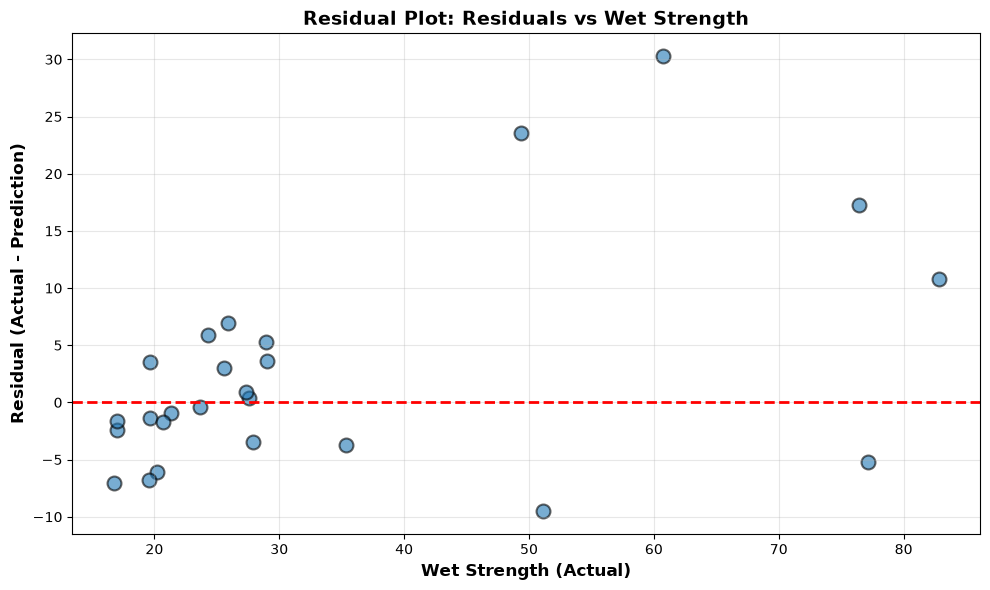

In [61]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(comparison_df['Actual'], comparison_df['Residual'], s=100, alpha=0.6, edgecolors='black', linewidth=1.5)
plt.axhline(y=0, color='r', linestyle='--', linewidth=2)
plt.xlabel('Wet Strength (Actual)', fontsize=12, fontweight='bold')
plt.ylabel('Residual (Actual - Prediction)', fontsize=12, fontweight='bold')
plt.title('Residual Plot: Residuals vs Wet Strength', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
# make inference based on a formulation

from sklearn import gaussian_process

mean_prediction, std_prediction = model.predict([[.5,-0.959381,np.nan,np.nan,np.nan]], return_std=True) 
print(mean_prediction, std_prediction)

ValueError: Input X contains NaN.
GaussianProcessRegressor does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values